# Task 1: Model Compression - Pruning and Quantization

Name: Muhammad Danish Zaheer Awan | REG id: 25280092

Compare magnitude/Wanda pruning, sensitivity-based allocation, asymmetric group PTQ,
AWQ-style scaling, mixed precision, and a 2:4 diagnostic on the **base** Qwen2.5-1.5B.
No fine-tuning is performed. All 18 mandatory conditions share fixed data and scoring.

**Colab:** compute/resume and verify Drive backups. **Local ATML environment:** replay
downloaded cloud evidence. Missing replay results raise an error; they never start training.
See `README.md` for upload locations, recovery, representation conventions, and limitations.


## Common setup

Keep `DRIVE_PROJECT` equal to your upload path relative to MyDrive, including both
parent folders (`ATML_PA4/PA_4`). On Colab, this notebook runs
the full protocol. Locally, its default is replay. Use the same GPU type and installed
environment when resuming a run; incompatible outputs are rejected.


In [1]:
# Name : Muhammad Danish Zaheer Awan
# REG id : 25280092
from importlib.util import find_spec
from pathlib import Path
import sys

try:
    IN_COLAB = find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
RUN_MODE = "compute" if IN_COLAB else "replay"
DRIVE_PROJECT = "ATML_PA4/PA_4"
DATA_SOURCE_FOLDER = "atml-pa4-datasets-main"
print(f"Task_1 | mode={RUN_MODE} | Colab={IN_COLAB}")


Task_1 | mode=replay | Colab=False


### Drive mount and fast local Colab storage

Upload only the complete `Task_1/` folder under `MyDrive/ATML_PA4/PA_4/` and open
`Task_1/main_task_1.ipynb`. Its bundled course setup files remove the need for a
separate Data upload. Code is copied to `/content/ATML_PA4/PA_4/`; results are saved to
`MyDrive/ATML_PA4/PA_4/Task_1/results/` throughout execution.


In [2]:
import shutil

if RUN_MODE == "compute":
    from google.colab import drive
    drive.mount("/content/drive")
    drive_root = Path("/content/drive/MyDrive") / DRIVE_PROJECT
    PROJECT_ROOT = Path("/content") / DRIVE_PROJECT
    if not (drive_root / "Task_1/main_task_1.ipynb").is_file():
        raise FileNotFoundError(f"Upload Task_1 under {drive_root} first.")
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
    shutil.copytree(drive_root / "Task_1", PROJECT_ROOT / "Task_1", dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("results", "__pycache__", ".ipynb_checkpoints"))
else:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / "Task_1/configs/base.yaml").is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError("Open the notebook from the PA4 root or Task_1 folder.")
sys.path.insert(0, str(PROJECT_ROOT))


### Dependencies

Compute uses the supplied Transformers/Hub pins and the documented project pins.
If an already loaded dependency changes, restart the Colab session and Run All.
Local replay uses the existing ATML environment and never installs compute packages.


In [3]:
if RUN_MODE == "compute":
    from Task_1.cloud.dependencies import install_compute_requirements
    install_compute_requirements(PROJECT_ROOT / "Task_1")
else:
    print("Local replay: skipping compute dependencies, Drive, and model downloads.")


Local replay: skipping compute dependencies, Drive, and model downloads.


In [4]:
import pandas as pd
from IPython.display import display
from Task_1.common.config import load_configuration
from Task_1.common.session import open_session
from Task_1.analysis.presentation import display_question

pd.set_option("display.max_rows", 24)
configuration = load_configuration(PROJECT_ROOT / "Task_1")
configuration["execution"]["drive_project"] = DRIVE_PROJECT
configuration["execution"]["source_folder"] = DATA_SOURCE_FOLDER
print("Project:", PROJECT_ROOT)
print("Run:", configuration["execution"]["run_id"])


Project: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_4
Run: task1_seed6304_v1


### Small correctness checks

These tests use tiny matrices and a randomly initialized tiny Qwen, never pretrained
downloads. They check pruning, packing, allocation, causal NLL, compensation/folding,
independent restoration, and verified recovery. They do not replace final experiments.


In [5]:
if RUN_MODE == "compute":
    import unittest
    import torch
    previous_threads = torch.get_num_threads()
    suite = unittest.defaultTestLoader.discover(str(PROJECT_ROOT / "Task_1/tests"))
    outcome = unittest.TextTestRunner(verbosity=1).run(suite)
    torch.set_num_threads(previous_threads)
    if not outcome.wasSuccessful():
        raise RuntimeError("Correctness checks failed; full experiments have not started.")
else:
    print("Replay: using saved evidence; compute diagnostics are skipped.")


Replay: using saved evidence; compute diagnostics are skipped.


### Restore or validate saved progress

Compute restores files from Drive using the backup index and checksums before
opening a stage. Calibration checkpoints every 16 sequences, each projection search
and development candidate saves when complete, and evaluation saves every 16
examples/windows. Local replay validates the complete downloaded evidence, including
sample counts and regenerated aggregate scores. Incompatible runs are never merged.


In [6]:
session = open_session(configuration, PROJECT_ROOT, RUN_MODE)
print("Results:", session.paths["results"])


Replay only | original execution: Google Colab | run task1_seed6304_v1
Results: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_4\Task_1\results\task1_seed6304_v1


In [7]:
def show_stage(records):
    "Show compact completion states while preserving full saved measurements."
    rows = [{"condition": row["condition"], "status": row["status"],
             "WikiText-2 PPL": row.get("quality", {}).get("wikitext2", {}).get("perplexity"),
             "C4 PPL": row.get("quality", {}).get("c4", {}).get("perplexity"),
             "HellaSwag acc_norm": row.get("quality", {}).get("hellaswag", {}).get("accuracy_normalized")}
            for row in records]
    display(pd.DataFrame(rows))


## Data download and preparation

Use the supplied candidate/validation IDs unchanged. The course `--public` script
and fixed manifests are included under `Task_1/resources/course_data/`. Compute
stages their unchanged copies under runtime `Data/` before downloading datasets.
The materializer produces 128 x 512 C4 calibration tokens, 32 separate development sequences,
two independent 50,000-scored-token suites, and 2,000 HellaSwag examples.
First-run immutable HF revisions, token windows, IDs, hashes, and disjointness checks
are saved and backed up. The first 512 HellaSwag IDs are the diagnostic subset.


In [8]:
display(session.prepare_data())


{'calibration_sequences': 128,
 'development_sequences': 32,
 'calibration_tokens_per_sequence': 512,
 'wikitext2_scored_tokens': 50000,
 'c4_scored_tokens': 50000,
 'hellaswag_examples': 2000,
 'hellaswag_diagnostic_orders': [0, 512],
 'leakage_checks': 'passed'}

## Step 1: Unchanged FP16 baseline and measurement protocol

Before **any held-out scoring**, collect shared calibration statistics, probe
projection sensitivity, choose P3 hyperparameters using only the 32 development
sequences, and freeze P3/Q3 maps. This early lock prevents baseline results from
influencing adaptive choices. Later steps apply these already frozen maps.

The unchanged model first selects a GPU batch/logit-chunk policy using calibration
inputs only, targeting useful throughput with 10% memory headroom. Quality and
development scoring reuse that saved policy; calibration batches stay within
16-sequence checkpoints. Masked padding never enters a scored-token denominator.
The separate latency benchmark batch size (default 1) is fixed across all methods
and may be configured before the run; Task 1 does not prescribe a batch size.

The scorer excludes every independent sequence's first token and scores each target
once. HellaSwag uses zero-shot conditional log likelihood and character normalization.
All conditions measure dense FP16 execution separately from estimated packed bytes.


In [9]:
display(session.prepare_calibration_and_plan())


{'status': 'saved cloud calibration/selection complete',
 'allocation_lock_id': '88fc72233452b42bf97e446aa3150c57c320eb70572905f4c9d2e997337a3c27'}

In [10]:
show_stage(session.run_group("fp16"))


,condition,status,WikiText-2 PPL,C4 PPL,HellaSwag acc_norm
0,fp16,complete,16.107384,14.962618,0.694


## Step 2: P1: Magnitude pruning

Prune the smallest absolute weights per output row at 25%, 50%, and 75%. Each condition restores the unchanged checkpoint; excluded parameters remain byte-identical.

Each stage resumes compatible per-example progress or displays its saved completion state.


In [11]:
show_stage(session.run_group('P1'))


,condition,status,WikiText-2 PPL,C4 PPL,HellaSwag acc_norm
0,p1_s25,complete,2.133057e+01,1.798671e+01,0.587891
1,p1_s50,complete,1.278006e+02,1.024490e+02,0.400000
2,p1_s75,complete,1.594711e+06,1.222062e+06,0.279297


## Step 3: P2: Activation-aware Wanda pruning

Use |W_ij| times the full-calibration input-feature L2 norm, with the same row quotas and sparsities as P1. Save score distributions and local output distortion.

Each stage resumes compatible per-example progress or displays its saved completion state.


In [12]:
show_stage(session.run_group('P2'))


,condition,status,WikiText-2 PPL,C4 PPL,HellaSwag acc_norm
0,p2_s25,complete,16.551763,15.389105,0.593750
1,p2_s50,complete,25.493806,21.225266,0.582000
2,p2_s75,complete,63667.355819,51801.429565,0.296875


## Step 4: P3: Nonuniform Wanda allocation

Apply the frozen projection-wise sensitivity allocation at global 50% and 75%. Ranking stays Wanda-based; sparsities remain within [0.10, 0.85], and integer zero counts match exactly. The temperature was selected before test evaluation.

Each stage resumes compatible per-example progress or displays its saved completion state.


In [13]:
show_stage(session.run_group('P3'))


,condition,status,WikiText-2 PPL,C4 PPL,HellaSwag acc_norm
0,p3_s50,complete,63.618390,44.478363,0.448000
1,p3_s75,complete,14529.256919,13780.241244,0.287109


## Step 5: Q1: Uniform asymmetric group PTQ

Evaluate INT8, INT4, and INT3 with 128 input-column groups. Use ties-to-even rounding, stored FP16 group scales, uint8 zero-points, zero-inclusive min/max ranges, and the documented row-aligned bit stream.

Each stage resumes compatible per-example progress or displays its saved completion state.


In [14]:
show_stage(session.run_group('Q1'))


,condition,status,WikiText-2 PPL,C4 PPL,HellaSwag acc_norm
0,q1_int8,complete,16.085528,14.968321,0.582031
1,q1_int4,complete,18.895928,16.728668,0.670000
2,q1_int3,complete,40.537992,30.570003,0.561500


## Step 6: Q2: AWQ-style activation scaling

Search only the recorded calibration scale grid. Verify rescaling before quantization. Fold the down inverse into compatible up-projection rows; retain and account for independent channel compensations elsewhere. This is a simplified AWQ-style implementation, not an optimized AWQ inference engine.

Each stage resumes compatible per-example progress or displays its saved completion state.


In [15]:
show_stage(session.run_group('Q2'))


,condition,status,WikiText-2 PPL,C4 PPL,HellaSwag acc_norm
0,q2_int8,complete,16.124763,14.965880,0.582031
1,q2_int4,complete,17.700935,15.952424,0.671000
2,q2_int3,complete,26.076572,21.600567,0.603500


## Step 7: Q3: Sensitivity-guided mixed precision

Apply the frozen greedy calibration-distortion allocation with bits {2,3,4,8}. Use exactly the Q2 scale search/quantizer; only bit assignments change. Total bytes include excluded weights, compensation, scales, zero-points, headers, and padding and cannot exceed Q2 INT4/INT3 budgets.

Each stage resumes compatible per-example progress or displays its saved completion state.


In [16]:
show_stage(session.run_group('Q3'))


,condition,status,WikiText-2 PPL,C4 PPL,HellaSwag acc_norm
0,q3_budget_int4,complete,20.107900,17.588130,0.661
1,q3_budget_int3,complete,35.832665,28.116984,0.535


## Step 8: Structured 2:4 Wanda diagnostic

Keep the two highest Wanda-ranked entries in each group of four contiguous input columns. Compare quality and representation with unstructured 50% Wanda; no T4 sparse-tensor-core acceleration is claimed.

Each stage resumes compatible per-example progress or displays its saved completion state.


In [17]:
show_stage(session.run_group('structured'))


,condition,status,WikiText-2 PPL,C4 PPL,HellaSwag acc_norm
0,wanda_2of4,complete,67.925144,51.420852,0.445312


## Step 9: Resource-quality comparisons and required evidence

Rebuild tables and figures from saved measurements. Compute paired 95% bootstrap
intervals for P3-P2 and Q3-Q2: resample HellaSwag examples and whole prediction
windows; pool token NLL before exponentiating. Failed conditions remain visible.
This step does not retrain or reload a model for plotting.

Local Windows replay also renders all figure text in **Times New Roman, 10 pt**
directly under `figures/` as the main report figures. Figure checksums are updated
with local formatting provenance; saved numerical measurements remain unchanged.


In [18]:
display(session.build_evidence())
if RUN_MODE == "replay":
    from Task_1.analysis.presentation import format_saved_figures
    display(format_saved_figures(session))


{'status': 'complete',
 'research_questions': ['rq1', 'rq2', 'rq3', 'rq4'],
 'source': 'Google Colab'}

{'status': 'rendered and registered main figures',
 'figures': 5,
 'font': 'Times New Roman, 10 pt',
 'directory': 'C:\\Users\\DanishZaheer\\Desktop\\LUMS\\Semester_3\\ATML\\PA_4\\Task_1\\results\\task1_seed6304_v1\\figures'}

## Required evaluation audit

Every required condition attempts both perplexity suites. Full HellaSwag is used for
FP16, P1/P2/P3 at 50%, and all INT4/INT3 quantization variants; other conditions use
the first 512 IDs. The table distinguishes counts and compares FP16 on paired IDs.
Timing uses two warmups and at least five synchronized repetitions at fixed shapes
and the same declared benchmark batch size for every condition.


In [19]:
audit = pd.read_csv(session.paths["results"] / "tables/all_conditions.csv")
display(audit[["condition", "status", "wikitext2_scored_tokens", "c4_scored_tokens",
               "hellaswag_required_examples", "hellaswag_evaluated_examples"]])


,condition,status,wikitext2_scored_tokens,c4_scored_tokens,hellaswag_required_examples,hellaswag_evaluated_examples
0,fp16,complete,50000,50000,2000,2000
1,p1_s25,complete,50000,50000,512,512
2,p1_s50,complete,50000,50000,2000,2000
3,p1_s75,complete,50000,50000,512,512
4,p2_s25,complete,50000,50000,512,512
5,p2_s50,complete,50000,50000,2000,2000
6,p2_s75,complete,50000,50000,512,512
7,p3_s50,complete,50000,50000,2000,2000
8,p3_s75,complete,50000,50000,512,512
9,q1_int8,complete,50000,50000,512,512


# Required evidence

The sections below display saved cloud measurements. Write your own interpretation after inspecting the results; the PDF report's language, interpretation, and analysis must be your own.


## RQ-1: Magnitude, activation, and removal impact

Compare local magnitude/Wanda reconstruction errors across sparsities and relate their differences to activation outliers. Complete projection score distributions are preserved in metrics/sensitivity_profiles.json.


In [20]:
display_question(session, 'rq1', 'tables')


tables/pruning_local_errors.csv
Showing the first 20 of 1568 saved rows; the complete table is in the CSV.


,projection,family,sparsity,relative_mse,squared_error,squared_reference,sample_tokens
0,model.layers.0.self_attn.q_proj,magnitude,0.25,0.000694,8.824144e+03,1.272152e+07,512
1,model.layers.0.self_attn.q_proj,magnitude,0.50,0.008359,1.063356e+05,1.272152e+07,512
2,model.layers.0.self_attn.q_proj,magnitude,0.75,0.062347,7.931426e+05,1.272152e+07,512
3,model.layers.0.self_attn.q_proj,wanda,0.10,0.000011,1.418975e+02,1.272152e+07,512
4,model.layers.0.self_attn.q_proj,wanda,0.25,0.000233,2.965444e+03,1.272152e+07,512
5,model.layers.0.self_attn.q_proj,wanda,0.50,0.005191,6.603209e+04,1.272152e+07,512
6,model.layers.0.self_attn.q_proj,wanda,0.75,0.049658,6.317314e+05,1.272152e+07,512
7,model.layers.0.self_attn.q_proj,wanda,0.85,0.105722,1.344942e+06,1.272152e+07,512
8,model.layers.0.self_attn.k_proj,magnitude,0.25,0.012354,1.981885e+03,1.604240e+05,512
9,model.layers.0.self_attn.k_proj,magnitude,0.50,0.066698,1.069999e+04,1.604240e+05,512


figures/rq1_pruning_mechanism.png


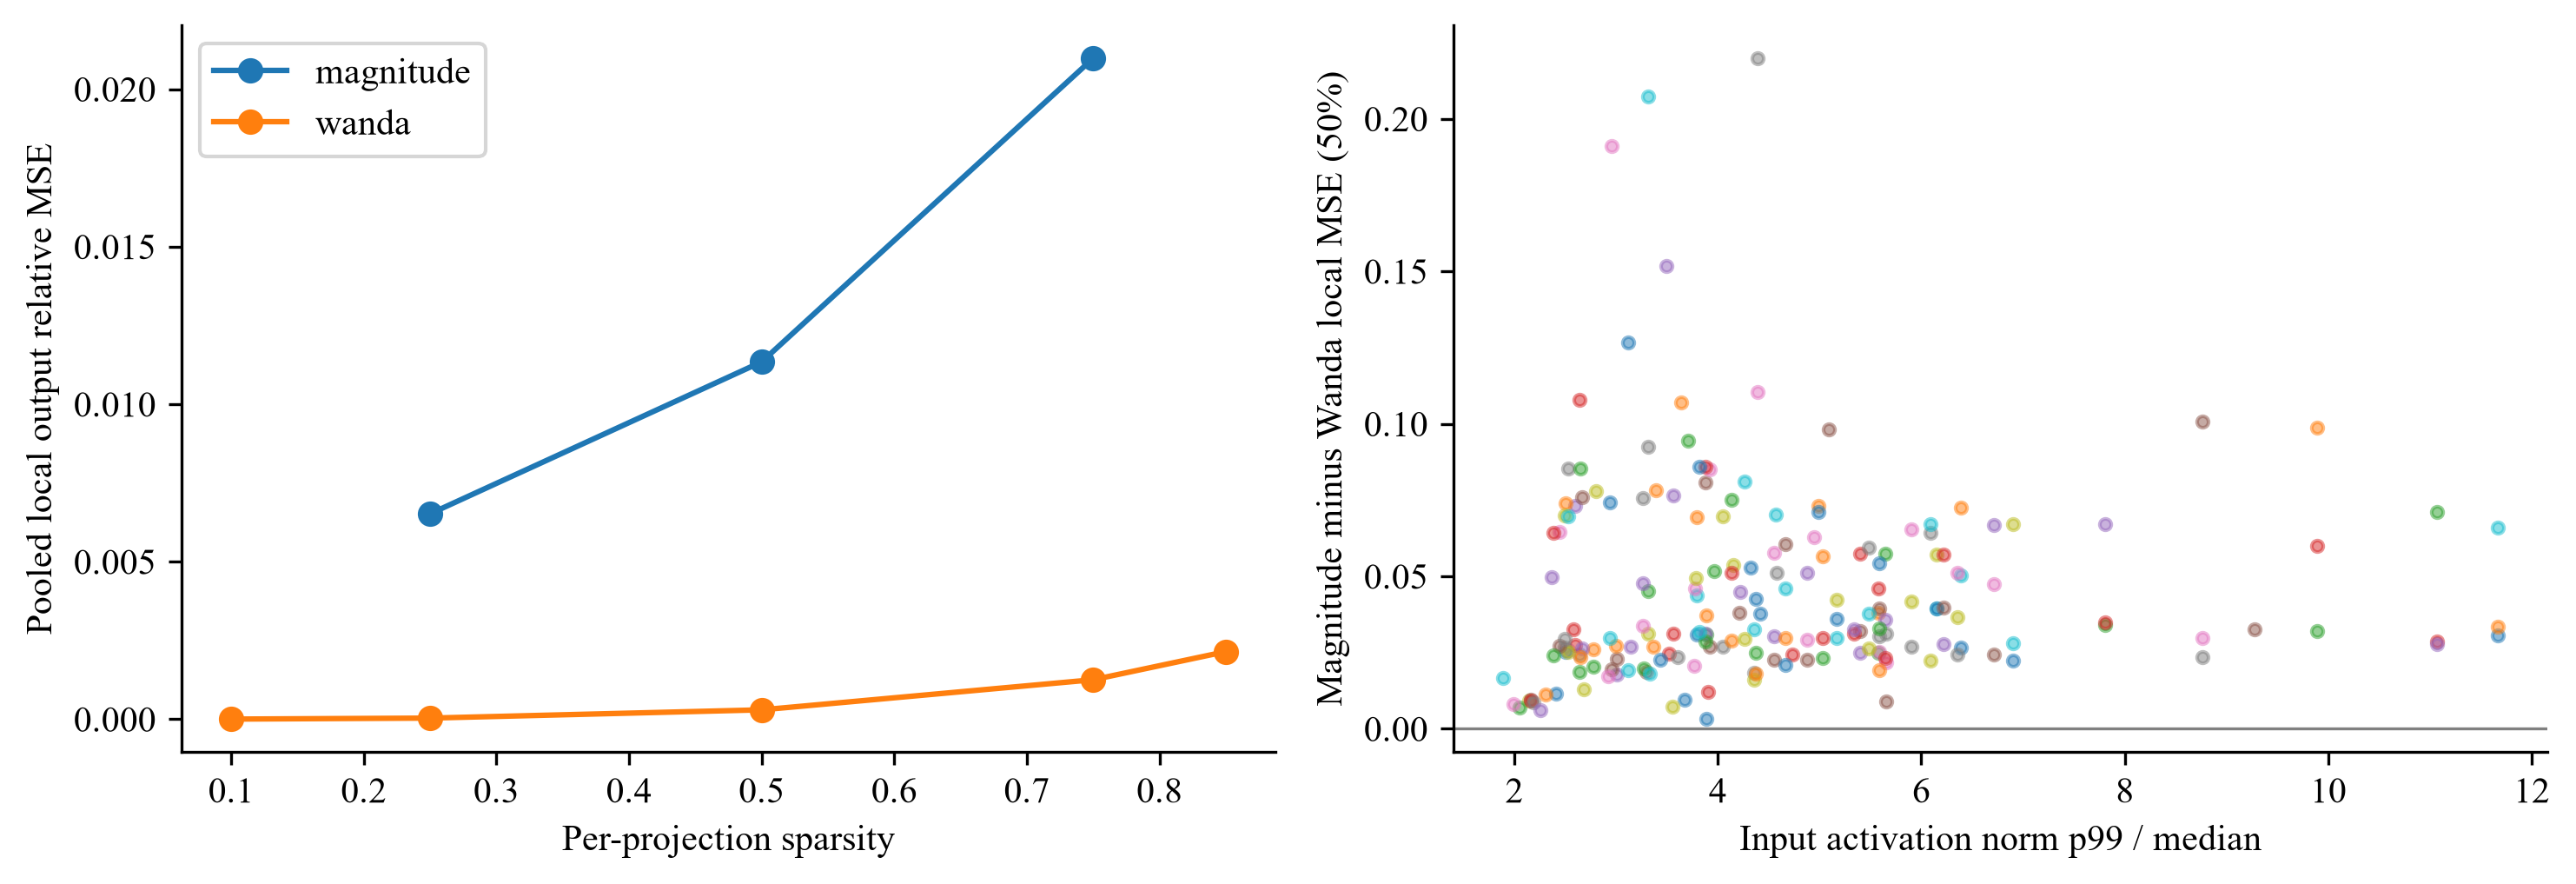

In [21]:
display_question(session, 'rq1', 'figures')


In [22]:
display_question(session, 'rq1', 'metrics')


## RQ-2: Sensitivity and constrained resource allocation

Inspect pruning and quantization sensitivity maps, selected sparsities/bits, and exact budget checks. Isolated projection errors do not capture every interaction after simultaneous compression.


In [23]:
display_question(session, 'rq2', 'tables')


tables/sensitivity_and_allocations.csv
Showing the first 20 of 196 saved rows; the complete table is in the CSV.


,projection,layer,component,elements,pruning_sensitivity,quantization_sensitivity,probe_seconds,activation_norm_median,activation_norm_p99,magnitude_median,wanda_score_median,p3_sparsity_0.5,p3_sparsity_0.75,q3_bits_budget_int4,q3_bits_budget_int3
0,model.layers.0.self_attn.q_proj,0,q_proj,2359296,0.005191,0.003297,0.101044,84.927643,329.999634,0.022461,1.798732,0.682575,0.850000,3,2
1,model.layers.0.self_attn.k_proj,0,k_proj,393216,0.029597,0.036195,0.047071,84.927643,329.999634,0.033691,2.771869,0.441714,0.781741,4,3
2,model.layers.0.self_attn.v_proj,0,v_proj,393216,0.029209,0.045124,0.051064,84.927643,329.999634,0.011841,0.952587,0.443176,0.786924,4,4
3,model.layers.0.self_attn.o_proj,0,o_proj,2359296,0.028148,0.031011,0.071725,59.563122,232.633163,0.013489,0.646315,0.447295,0.801618,4,3
4,model.layers.0.mlp.gate_proj,0,gate_proj,13762560,0.014245,0.014271,0.161546,57.150597,171.884415,0.019897,1.259357,0.530320,0.850000,4,3
5,model.layers.0.mlp.up_proj,0,up_proj,13762560,0.032059,0.031259,0.148713,57.150597,171.884415,0.016846,1.067779,0.432978,0.751123,4,3
6,model.layers.0.mlp.down_proj,0,down_proj,13762560,0.028791,0.029144,0.140673,21.274616,80.086258,0.017578,0.399063,0.444774,0.792609,4,3
7,model.layers.1.self_attn.q_proj,1,q_proj,2359296,0.015712,0.016184,0.051345,62.835896,273.734558,0.019653,1.300160,0.517483,0.850000,4,3
8,model.layers.1.self_attn.k_proj,1,k_proj,393216,0.014758,0.015021,0.052077,62.835896,273.734558,0.025635,1.714785,0.525650,0.849998,4,3
9,model.layers.1.self_attn.v_proj,1,v_proj,393216,0.025993,0.029602,0.043634,62.835896,273.734558,0.012939,0.868141,0.456291,0.834183,4,3


tables/budget_checks.csv


,method,target,required_zeros,allocated_zeros,temperature,development_mean_nll,matched,reference_bytes,allocated_bytes,unused_bytes
0,p3_s50,0.50,655097856.0,655097856.0,0.25,3.572948,True,NaN,NaN,NaN
1,p3_s75,0.75,982646784.0,982646784.0,0.50,9.248009,True,NaN,NaN,NaN
2,q3_budget_int4,NaN,NaN,NaN,NaN,NaN,True,1.153372e+09,1.153372e+09,0.0
3,q3_budget_int3,NaN,NaN,NaN,NaN,NaN,True,9.895971e+08,9.895971e+08,0.0


figures/rq2_sensitivity_and_allocations.png


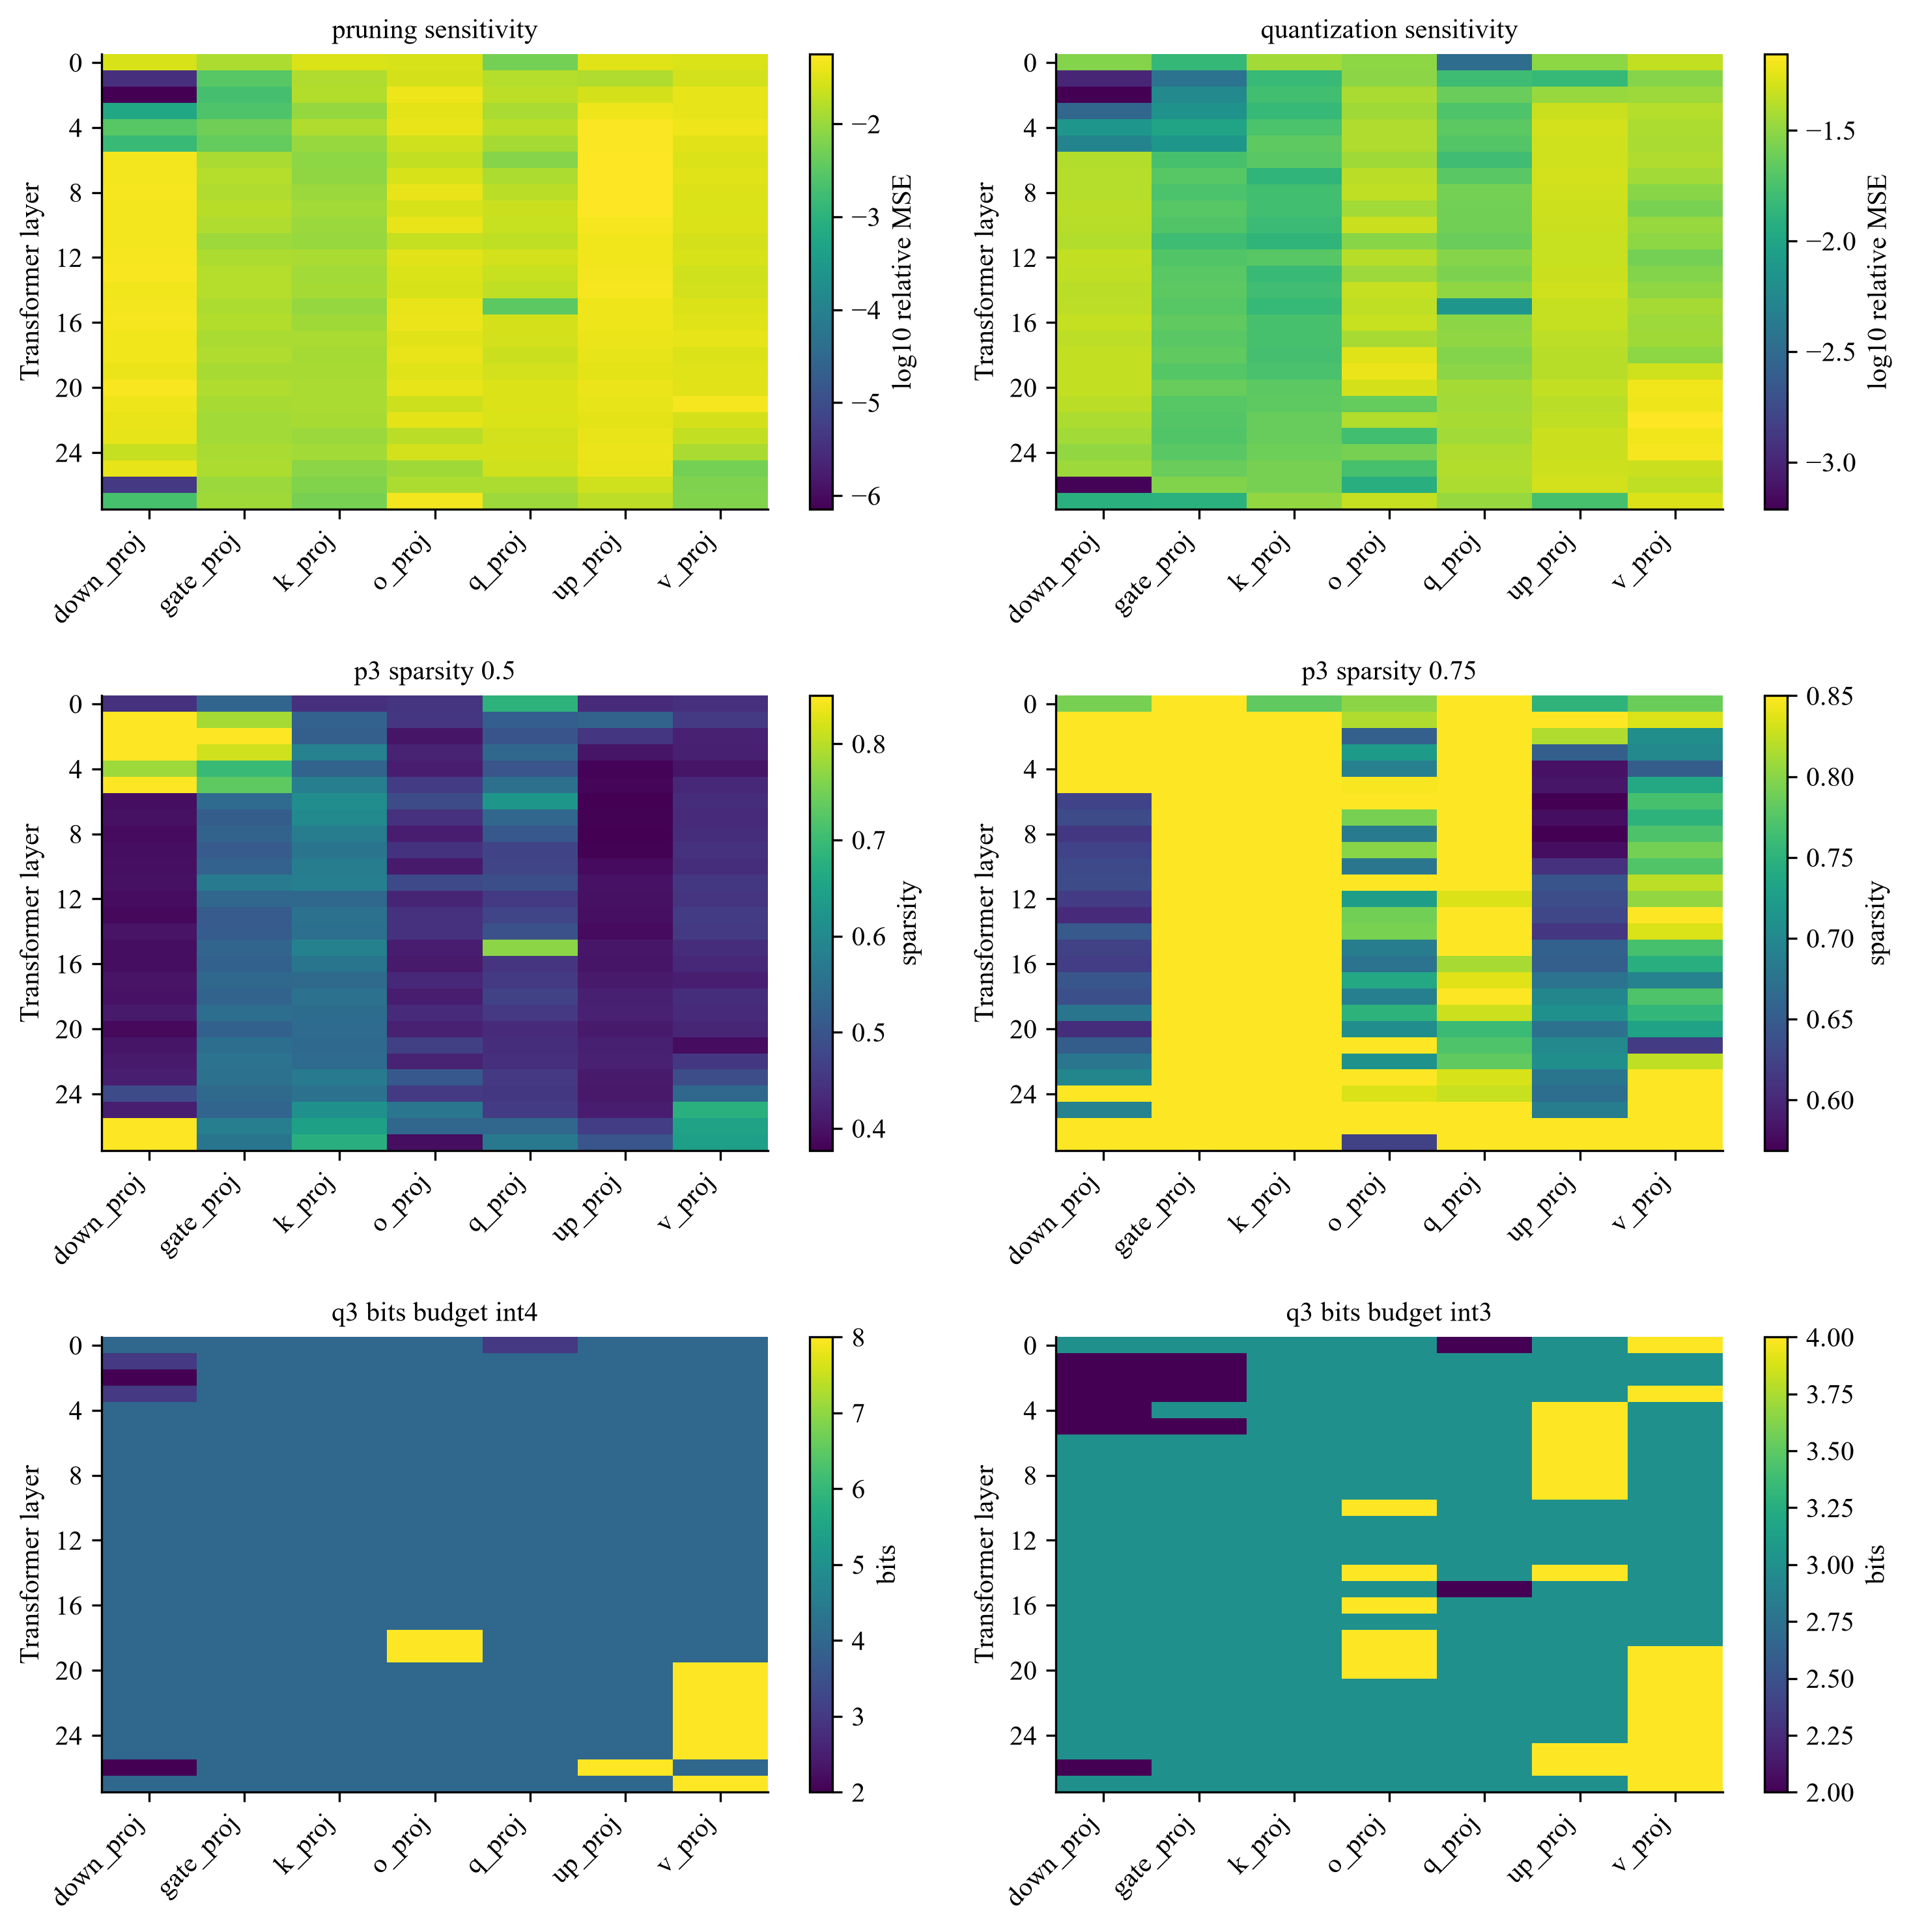

In [24]:
display_question(session, 'rq2', 'figures')


In [25]:
display_question(session, 'rq2', 'metrics')


## RQ-3: Matched-budget quality and metric agreement

Use pooled likelihood, raw/normalized answer selection, paired intervals, and aligned candidate-score examples. HellaSwag diagnostic plots use the same 512 IDs for every condition.


In [26]:
display_question(session, 'rq3', 'tables')


tables/all_conditions.csv


,condition,family,status,hellaswag_required_examples,compression_seconds,condition_peak_allocated_bytes,calibration_relative_mse,achieved_sparsity,estimated_packed_model_bytes,nominal_bits_per_eligible_weight,...,hellaswag_diagnostic_accuracy_normalized,hellaswag_paired_accuracy_delta,hellaswag_paired_normalized_accuracy_delta,hellaswag_paired_baseline_examples,prefill_512_median_ms,decode_512_64_steps_median_ms,peak_512_allocated_bytes,prefill_2048_median_ms,decode_2048_64_steps_median_ms,peak_2048_allocated_bytes
0,fp16,fp16,complete,2000,2.466085,9969477632,0.000000,0.000002,3087441280,16.0,...,0.582031,0.000000,0.000000,2000,34.180608,2109.521175,3146681856,49.789226,2078.338205,3292458496
1,p1_s25,P1,complete,512,4.797528,9969477632,0.011911,0.250000,2596117888,16.0,...,0.587891,-0.013672,0.005859,512,34.987592,2101.182775,3146681856,49.681386,2098.064122,3292458496
2,p1_s50,P1,complete,2000,4.765847,9969477632,0.069847,0.500000,1941020032,16.0,...,0.414062,-0.179500,-0.294000,2000,34.300772,2108.343925,3146681856,49.746127,2102.814662,3292458496
3,p1_s75,P1,complete,512,4.768531,9969477632,0.224946,0.750000,1285922176,16.0,...,0.279297,-0.181641,-0.302734,512,34.156229,2099.183242,3146681856,49.673960,2106.296198,3292458496
4,p2_s25,P2,complete,512,4.797188,9969477632,0.002830,0.250000,2596117888,16.0,...,0.593750,0.003906,0.011719,512,34.310566,2105.580856,3146681856,49.757500,2119.891295,3292458496
5,p2_s50,P2,complete,2000,4.795144,9969477632,0.024978,0.500000,1941020032,16.0,...,0.541016,-0.077500,-0.112000,2000,34.358517,2110.931305,3146681856,49.763105,2095.237705,3292458496
6,p2_s75,P2,complete,512,4.815003,9969477632,0.105500,0.750000,1285922176,16.0,...,0.296875,-0.193359,-0.285156,512,34.240149,2117.842030,3146681856,49.850752,2122.526275,3292458496
7,p3_s50,P3,complete,2000,4.846232,9969477632,0.018647,0.500000,1941021280,16.0,...,0.435547,-0.156500,-0.246000,2000,34.299297,2116.626773,3146681856,49.692012,2091.681946,3292458496
8,p3_s75,P3,complete,512,4.821554,9969477632,0.111641,0.750000,1285923024,16.0,...,0.287109,-0.187500,-0.294922,512,34.163387,2109.522683,3146681856,49.760931,2112.326088,3292458496
9,q1_int8,Q1,complete,512,5.850924,9969477632,0.000041,0.008892,1807953280,8.0,...,0.582031,-0.001953,0.000000,512,34.498222,2096.748307,3146681856,49.766574,2100.339103,3292458496


tables/paired_comparisons.csv


,method,reference,suite,status,metric,difference,ci_low,ci_high,overflow,paired_windows,scored_tokens,resamples,unit,resampling_unit,paired_examples
0,p3_s50,p2_s50,wikitext2,complete,mean_nll,0.914467,0.887539,0.941398,False,437.0,50000.0,2000,nats/token,"whole fixed evaluation windows, paired",NaN
1,p3_s50,p2_s50,wikitext2,complete,perplexity,38.124584,34.808064,41.913001,False,437.0,50000.0,2000,perplexity,"whole fixed evaluation windows, paired",NaN
2,p3_s50,p2_s50,c4,complete,mean_nll,0.739811,0.704034,0.777487,False,177.0,50000.0,2000,nats/token,"whole fixed evaluation windows, paired",NaN
3,p3_s50,p2_s50,c4,complete,perplexity,23.253097,20.628024,26.402608,False,177.0,50000.0,2000,perplexity,"whole fixed evaluation windows, paired",NaN
4,p3_s50,p2_s50,hellaswag,complete,accuracy,-0.079000,-0.094000,-0.064500,NaN,NaN,NaN,2000,fraction; multiply by 100 for percentage points,NaN,2000.0
5,p3_s50,p2_s50,hellaswag,complete,accuracy_normalized,-0.134000,-0.152000,-0.116000,NaN,NaN,NaN,2000,fraction; multiply by 100 for percentage points,NaN,2000.0
6,p3_s75,p2_s75,wikitext2,complete,mean_nll,-1.477508,-1.550248,-1.404605,False,437.0,50000.0,2000,nats/token,"whole fixed evaluation windows, paired",NaN
7,p3_s75,p2_s75,wikitext2,complete,perplexity,-49138.098900,-54570.686353,-43937.810706,False,437.0,50000.0,2000,perplexity,"whole fixed evaluation windows, paired",NaN
8,p3_s75,p2_s75,c4,complete,mean_nll,-1.324182,-1.578997,-1.046378,False,177.0,50000.0,2000,nats/token,"whole fixed evaluation windows, paired",NaN
9,p3_s75,p2_s75,c4,complete,perplexity,-38021.188321,-53773.748739,-25199.956212,False,177.0,50000.0,2000,perplexity,"whole fixed evaluation windows, paired",NaN


tables/qualitative_cases.csv
Showing the first 20 of 306 saved rows; the complete table is in the CSV.


,condition,order,gold,prediction,prediction_normalized,correct,correct_normalized,selection
0,fp16,0,3,1,3,0,1,fixed_manifest_order
1,fp16,1,0,2,2,0,0,fixed_manifest_order
2,fp16,2,3,2,0,0,0,fixed_manifest_order
3,fp16,3,2,2,1,1,0,fixed_manifest_order
4,fp16,4,2,3,2,0,1,fixed_manifest_order
5,fp16,5,1,1,0,1,0,fixed_manifest_order
6,fp16,6,3,3,3,1,1,fixed_manifest_order
7,fp16,7,1,1,1,1,1,fixed_manifest_order
8,fp16,9,3,0,2,0,0,first_four_adaptive_pair_disagreements
9,fp16,10,1,2,1,0,1,first_four_adaptive_pair_disagreements


figures/rq3_resource_quality.png


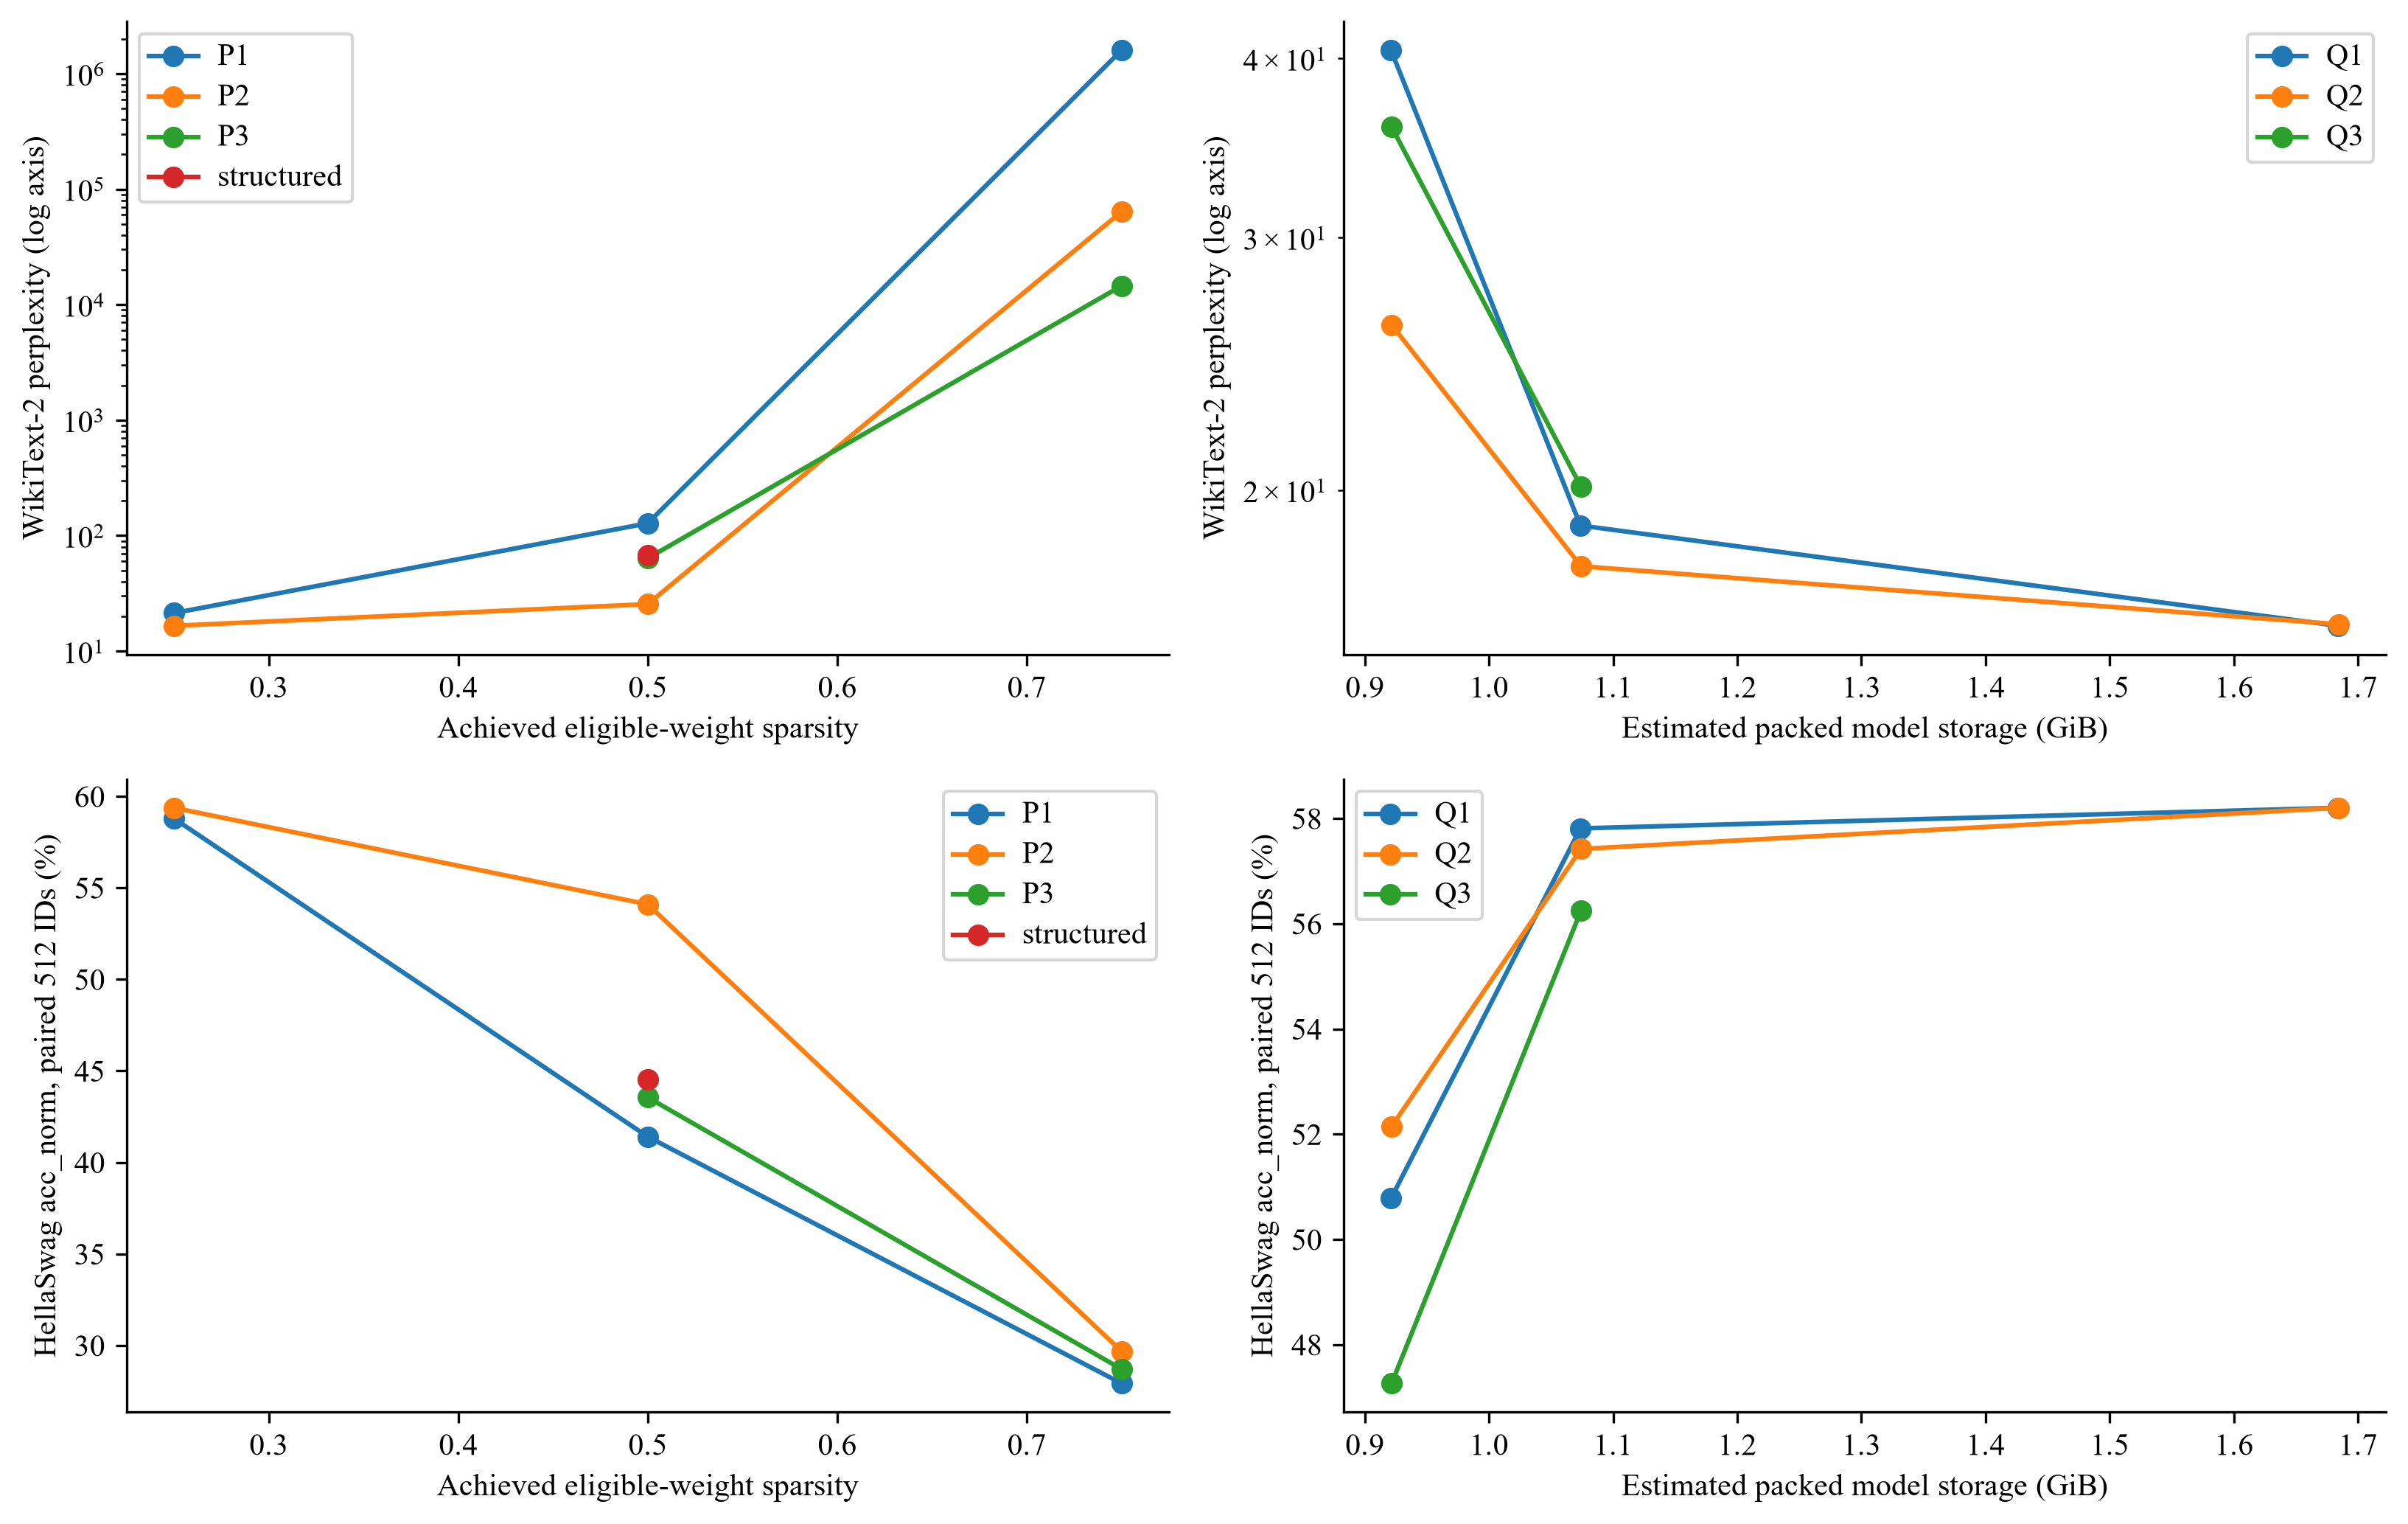

figures/rq3_calibration_vs_heldout.png


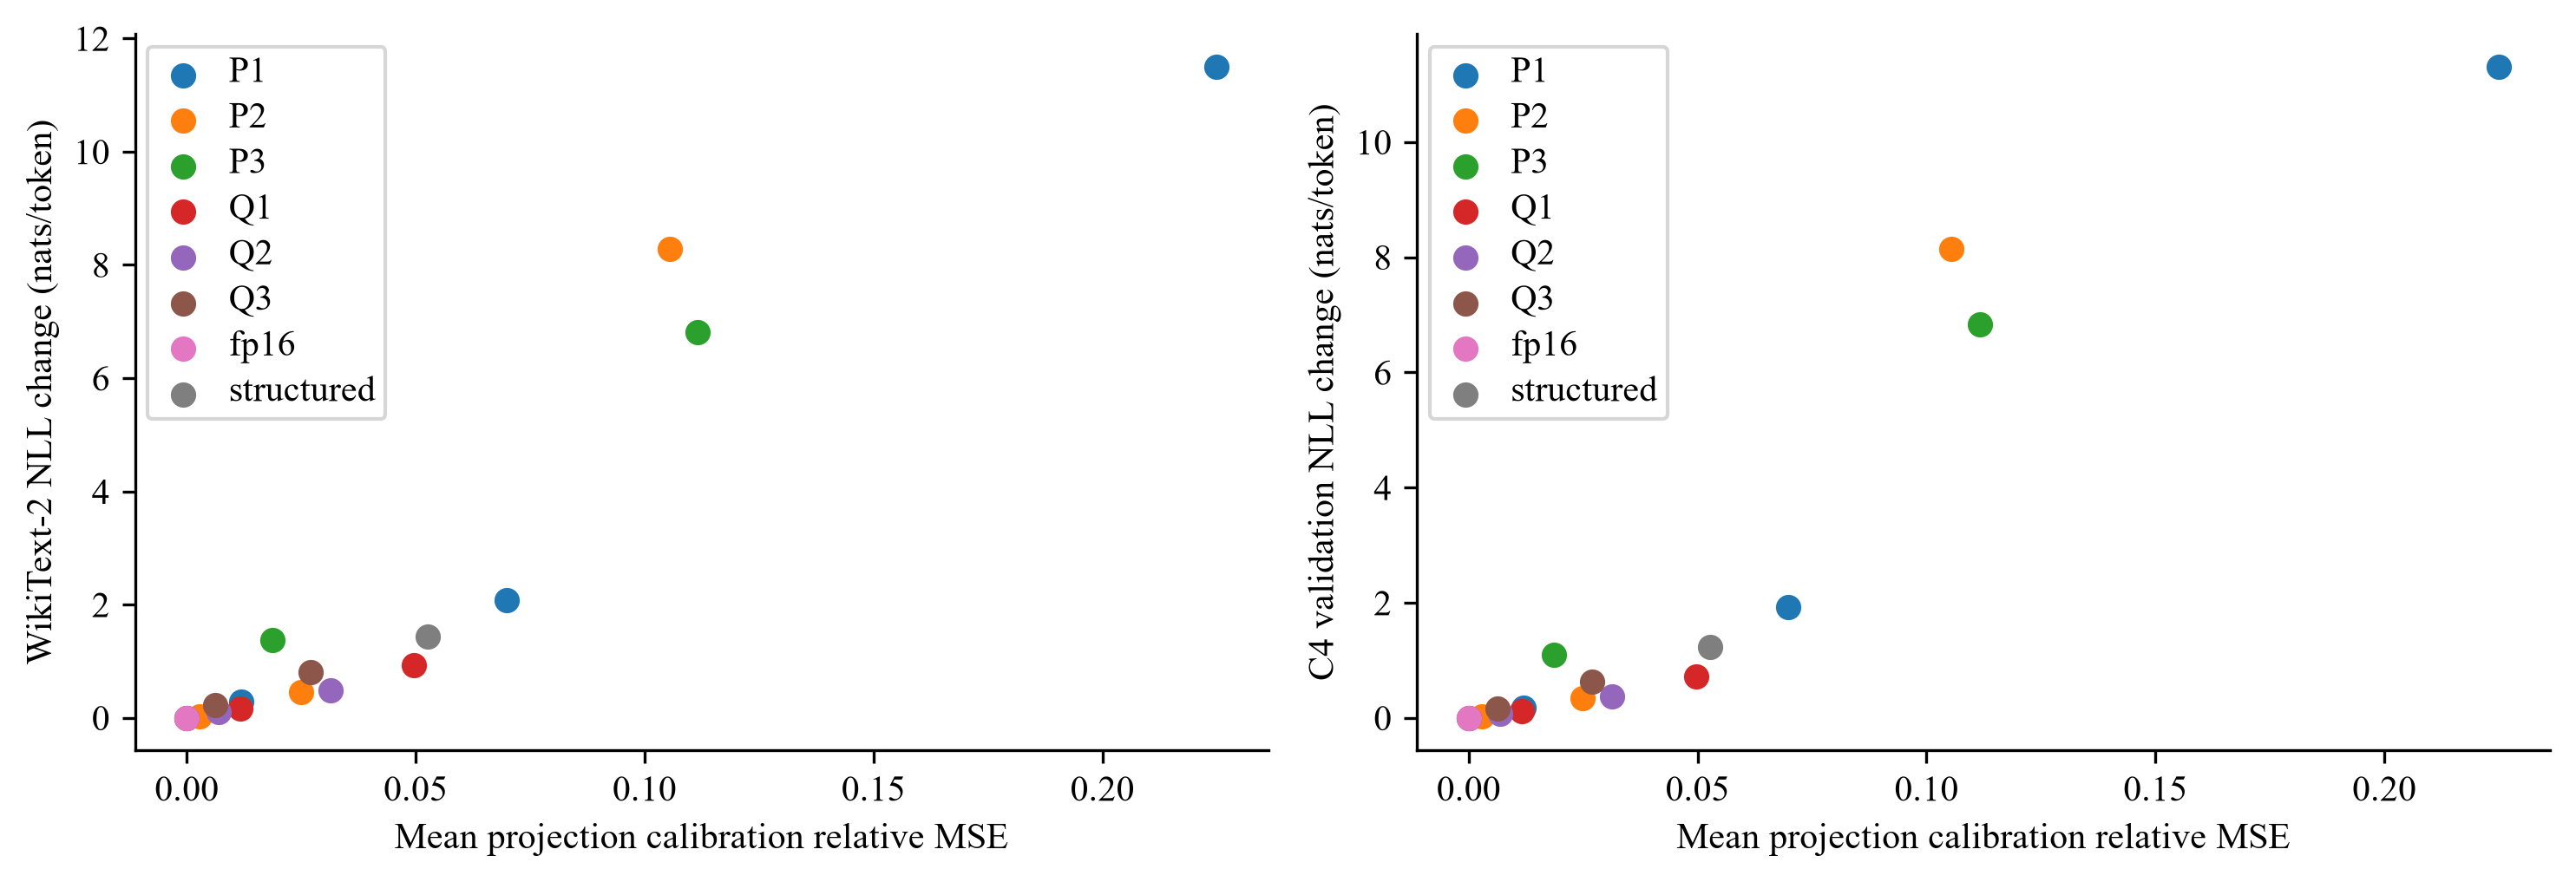

In [27]:
display_question(session, 'rq3', 'figures')


In [28]:
display_question(session, 'rq3', 'metrics')


metrics/calibration_vs_quality.json


[{'family': 'P1',
  'suite': 'wikitext2',
  'conditions': 3,
  'pearson_correlation': 0.9931524770113708,
  'note': 'descriptive across conditions; not a causal or generalization claim'},
 {'family': 'P1',
  'suite': 'c4',
  'conditions': 3,
  'pearson_correlation': 0.9927768448649359,
  'note': 'descriptive across conditions; not a causal or generalization claim'},
 {'family': 'P2',
  'suite': 'wikitext2',
  'conditions': 3,
  'pearson_correlation': 0.9872382510723821,
  'note': 'descriptive across conditions; not a causal or generalization claim'},
 {'family': 'P2',
  'suite': 'c4',
  'conditions': 3,
  'pearson_correlation': 0.985335707127019,
  'note': 'descriptive across conditions; not a causal or generalization claim'},
 {'family': 'P3',
  'suite': 'wikitext2',
  'conditions': 2,
  'pearson_correlation': None,
  'note': 'descriptive across conditions; not a causal or generalization claim'},
 {'family': 'P3',
  'suite': 'c4',
  'conditions': 2,
  'pearson_correlation': None,
  'n

## RQ-4: Calibration cost, representation overhead, and real execution

Compare estimated packed storage with measured dense FP16 memory and latency. Include activation collection, probe/search and development-selection costs; explicit AWQ compensation can add execution overhead.


In [29]:
display_question(session, 'rq4', 'tables')


tables/all_conditions.csv


,condition,family,status,hellaswag_required_examples,compression_seconds,condition_peak_allocated_bytes,calibration_relative_mse,achieved_sparsity,estimated_packed_model_bytes,nominal_bits_per_eligible_weight,...,hellaswag_diagnostic_accuracy_normalized,hellaswag_paired_accuracy_delta,hellaswag_paired_normalized_accuracy_delta,hellaswag_paired_baseline_examples,prefill_512_median_ms,decode_512_64_steps_median_ms,peak_512_allocated_bytes,prefill_2048_median_ms,decode_2048_64_steps_median_ms,peak_2048_allocated_bytes
0,fp16,fp16,complete,2000,2.466085,9969477632,0.000000,0.000002,3087441280,16.0,...,0.582031,0.000000,0.000000,2000,34.180608,2109.521175,3146681856,49.789226,2078.338205,3292458496
1,p1_s25,P1,complete,512,4.797528,9969477632,0.011911,0.250000,2596117888,16.0,...,0.587891,-0.013672,0.005859,512,34.987592,2101.182775,3146681856,49.681386,2098.064122,3292458496
2,p1_s50,P1,complete,2000,4.765847,9969477632,0.069847,0.500000,1941020032,16.0,...,0.414062,-0.179500,-0.294000,2000,34.300772,2108.343925,3146681856,49.746127,2102.814662,3292458496
3,p1_s75,P1,complete,512,4.768531,9969477632,0.224946,0.750000,1285922176,16.0,...,0.279297,-0.181641,-0.302734,512,34.156229,2099.183242,3146681856,49.673960,2106.296198,3292458496
4,p2_s25,P2,complete,512,4.797188,9969477632,0.002830,0.250000,2596117888,16.0,...,0.593750,0.003906,0.011719,512,34.310566,2105.580856,3146681856,49.757500,2119.891295,3292458496
5,p2_s50,P2,complete,2000,4.795144,9969477632,0.024978,0.500000,1941020032,16.0,...,0.541016,-0.077500,-0.112000,2000,34.358517,2110.931305,3146681856,49.763105,2095.237705,3292458496
6,p2_s75,P2,complete,512,4.815003,9969477632,0.105500,0.750000,1285922176,16.0,...,0.296875,-0.193359,-0.285156,512,34.240149,2117.842030,3146681856,49.850752,2122.526275,3292458496
7,p3_s50,P3,complete,2000,4.846232,9969477632,0.018647,0.500000,1941021280,16.0,...,0.435547,-0.156500,-0.246000,2000,34.299297,2116.626773,3146681856,49.692012,2091.681946,3292458496
8,p3_s75,P3,complete,512,4.821554,9969477632,0.111641,0.750000,1285923024,16.0,...,0.287109,-0.187500,-0.294922,512,34.163387,2109.522683,3146681856,49.760931,2112.326088,3292458496
9,q1_int8,Q1,complete,512,5.850924,9969477632,0.000041,0.008892,1807953280,8.0,...,0.582031,-0.001953,0.000000,512,34.498222,2096.748307,3146681856,49.766574,2100.339103,3292458496


figures/rq4_storage_memory_latency.png


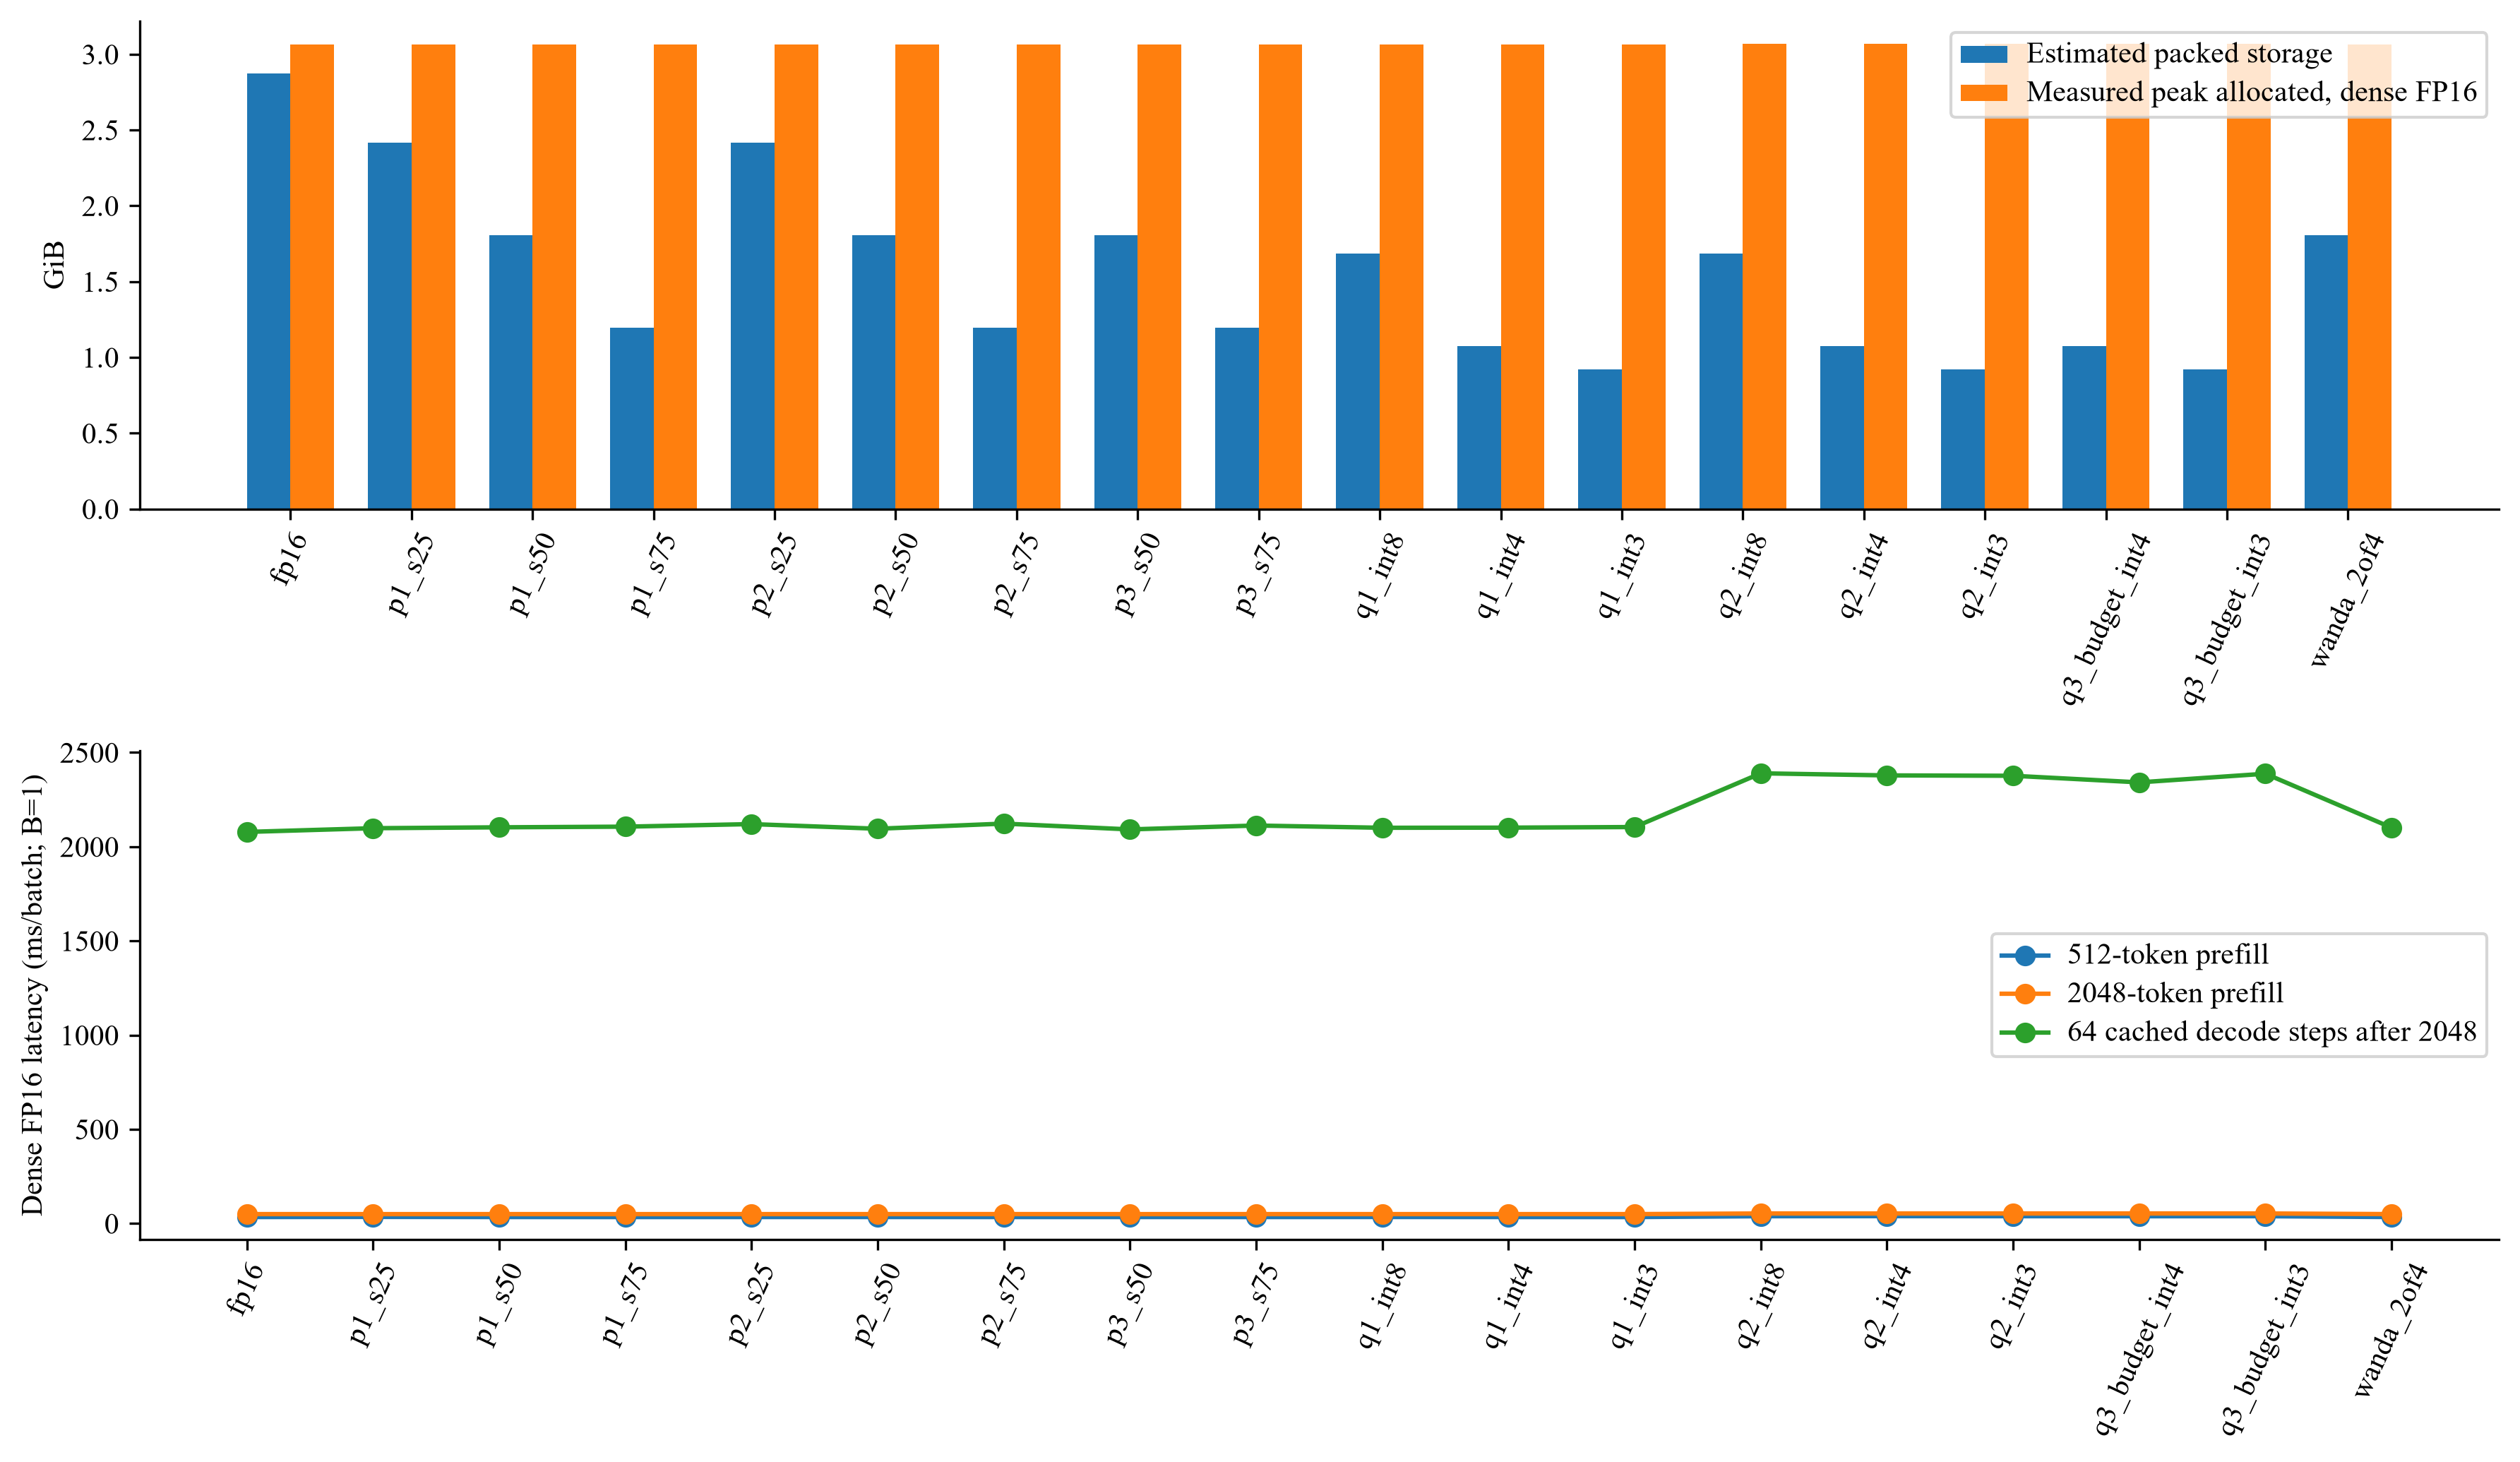

In [30]:
display_question(session, 'rq4', 'figures')


In [31]:
display_question(session, 'rq4', 'metrics')


metrics/calibration_and_selection_cost.json


{'activation_collection': {'seconds': 2.8580511349999824,
  'sequences': 128,
  'timing_scope': 'completed forwards and activation hooks; excludes checkpoint I/O and repeated unsaved work',
  'peak_allocated_bytes': 3944775168,
  'checkpoint_interval_sequences': 16,
  'resumed_from_sequences': 0,
  'batch_sequences': 16,
  'tokens_per_sequence': 512,
  'probe_positions_within_every_sequence': [0, 170, 341, 511],
  'probe_tokens_per_projection': 512,
  'feature_norm_tokens_per_projection': 65536,
  'note': 'Full calibration feature norms; fixed, recorded within-sequence subsampling for local error probes.'},
 'projection_probe_seconds': 16.989688239999964,
 'projection_probe_peak_allocated_bytes': 3670629376,
 'development_candidate_seconds': 31.52869453599999,
 'precision_allocation': 'deterministic greedy calibration distortion reduction per byte; no test selection',
 'selection_limitation': 'Isolated projection errors ignore accumulated cross-layer and folding interactions.',
 'gpu_w

### Aligned qualitative cases

Cases use fixed manifest orders plus the first four adaptive/reference normalized
prediction disagreements per declared pair. The JSON retains the same prompt,
four endings, gold label, and all raw/character-normalized scores for each method.


In [32]:
from Task_1.common.artifacts import read_json
examples = read_json(session.paths["results"] / "examples/hellaswag_aligned.json")
print(examples["selection_rule"])
display(examples["examples"][:3])


Fixed orders from configuration plus first four normalized-prediction disagreements per declared adaptive/reference pair, in manifest order.


[{'example_id': 'hellaswag:1',
  'condition': 'fp16',
  'suite': 'hellaswag',
  'order': 0,
  'source_row_index': 1,
  'prompt': 'Clean and jerk: A lady walks to a barbell. She bends down and grabs the pole. The lady',
  'endings': ['swings and lands in her arms.',
   'pulls the barbell forward.',
   'pulls a rope attached to the barbell.',
   'stands and lifts the weight over her head.'],
  'gold': 3,
  'log_likelihoods': [-28.578095823526382,
   -13.109806686639786,
   -17.366995185613632,
   -14.690244050696492],
  'character_lengths': [29, 26, 37, 42],
  'continuation_token_counts': [7, 6, 9, 9],
  'character_normalized_scores': [-0.9854515801215994,
   -0.5042233341015302,
   -0.4693782482598279,
   -0.34976771549277363],
  'prediction': 1,
  'prediction_normalized': 3,
  'correct': 0,
  'correct_normalized': 1,
  'prompt_sha256': 'cd488e6943ea50fa99c7e4f653ce99f18b6d4e6d53bcd980d9c3973aa95df1a9',
  'task_version': '1.0',
  'format_reference': "lm-evaluation-harness v0.4.9; zero-s

## Completion, verified backup, and results download

Validate all registered artifacts and numerical counts before declaring completion.
Download `MyDrive/ATML_PA4/PA_4/Task_1/results/` and place it at your local
`Task_1/results/`, keeping the run folder inside it. Drive may package a folder
download as a ZIP; extract that folder without adding `results/results`.
Open this same notebook locally in the ATML environment and Run All to validate
and display the cloud tables, figures and per-example evidence for analysis.


In [33]:
display(session.finish())


{'status': 'complete', 'source': 'Google Colab', 'run_id': 'task1_seed6304_v1'}